In [1]:
from google.colab import files
import pandas as pd

# Seleccionar y cargar el archivo de Excel
archivos = files.upload()

# Obtener el nombre del archivo cargado
nombre_archivo = next(iter(archivos))

# Leer la hoja que contiene los datos por país
df = pd.read_excel(
    nombre_archivo,
    sheet_name="Country dataset"
)

print("Archivo cargado correctamente")
print("Filas y columnas:", df.shape)

Saving What_a_Waste_3.0_COUNTRY_Dataset_&_Codebook.xlsx to What_a_Waste_3.0_COUNTRY_Dataset_&_Codebook.xlsx
Archivo cargado correctamente
Filas y columnas: (218, 110)


In [2]:
# Mostrar los primeros cinco registros
display(df.head())

# Consultar los nombres de las columnas
print("Columnas disponibles:")
print(df.columns.tolist())

# Revisar los tipos de datos
df.info()


,Country code,Region,Country name,Income group (waste generation year),Income group (2022),GDP,Population in waste generation year,MSW generation - year reported,MSW generation (t/y),MSW generation - point of measurement,...,Existence of EPR system for waste batteries,Existence of EPR system for other waste,EPR leadership model (private or government led),Mandatory or voluntary EPR,Operational status of EPR system,Existence of DRS for beverage containers,Geographical scope of DRS,DRS container scope,Driver of participation in DRS,Operational status of DRS
0,iso3c,region_id,country_name,income_id,income_id_2022,gdp,population_number_of_people,msw_total_msw_generation_year,msw_total_msw_generated_tonnes_year,msw_total_msw_generated_point_of_measurement,...,epr_(3)_batteries,epr_(6)_other,epr_Private_(industry_led)_or_public_(governme...,epr_mandatory_or_voluntary_scheme,epr_Operational_status,drs_for_beverage_containers_present,drs_geographical_scope,drs_containers_types,drs_mandatory_vs_voluntary,drs_operational_status
1,AFG,S. Asia,Afghanistan,LIC,LIC,18753456497.82,35174083,2017,4148162,Not stated,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ALB,Eur. & Cent. Asia,Albania,UMIC,UMIC,18032009220,2865704,2021,754094,"Point of treatment or disposal (Landfill, dump...",...,Yes,Yes,Industry-led,Mandatory,Legally-binding regulations in place,NaN,NaN,NaN,NaN,NaN
3,DZA,Mid. East & N. Africa,Algeria,LMIC,LMIC,164873415325.200012,43685420,2020,13500000,Not stated,...,NaN,NaN,NaN,Both,Legally-binding regulations in place,NaN,NaN,NaN,NaN,NaN
4,ASM,E. Asia & Pacific,American Samoa,UMIC,HIC,647000000,50563,2019,17348.1653,Not stated,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Columnas disponibles:
['Country code', 'Region', 'Country name ', 'Income group (waste generation year)', 'Income group (2022)', 'GDP', 'Population in waste generation year', 'MSW generation - year reported', 'MSW generation (t/y)', 'MSW generation - point of measurement', 'MSW generation (kg/capita/day)', 'MSW generation - projected 2022 (t/year)', 'Population in 2022', 'MSW generation - projected 2022 (kg/cap/day)', 'MSW generation - projected 2030 (t/y)', 'Population in 2030', 'MSW generation - projected 2030 (kg/cap/day)', 'MSW generation - projected 2040 (t/y)', 'Population in 2040', 'MSW generation - projected 2040 (kg/cap/day)', 'MSW generation - projected 2050 (t/y)', 'Population in 2050', 'MSW generation - projected 2050 (kg/cap/day)', 'Composition - food  (% weight MSW)', 'Composition - glass  (% weight MSW)', 'Composition - metal (% weight MSW)', 'Composition - paper & cardboard (% weight MSW)', 'Composition - plastic (% weight MSW)', 'Composition - rubber & leather  (% weig

In [3]:
# 1. Revisar si existen filas duplicadas
print("Filas duplicadas:", df.duplicated().sum())

# 2. Revisar los valores faltantes
faltantes = df.isnull().sum()
faltantes = faltantes[faltantes > 0].sort_values(ascending=False)

print("\nColumnas con valores faltantes:")
display(faltantes.to_frame(name="Valores faltantes"))

# 3. Revisar los nombres de las columnas clave
print("\nColumnas para nuestro análisis:")

display(
    df[[
        "Country name ",
        "Income group (2022)",
        "Treatment - recycling (% weight MSW generated)"
    ]].head(10)
)


Filas duplicadas: 0

Columnas con valores faltantes:


,Valores faltantes
Treatment - MBT (% weight MSW generated),213
Informal waste workers - children,213
Treatment - RDF (% weight MSW generated),212
Treatment - anaerobic digestion (% weight MSW generated),211
Informal waste workers - women,211
...,...
Existence of national department to enforce SWM laws and regulations,14
Name of national agency that enforces SWM laws and regulations,11
Existence of national law which governs SWM,10
Existence of national agency to enforce SWM laws and regulations,9



Columnas para nuestro análisis:


,Country name,Income group (2022),Treatment - recycling (% weight MSW generated)
0,country_name,income_id_2022,waste_treatment_recycling_percent
1,Afghanistan,LIC,0.189
2,Albania,UMIC,0.173337
3,Algeria,LMIC,0.07
4,American Samoa,HIC,NaN
5,Andorra,HIC,0.399
6,Angola,LMIC,NaN
7,Antigua and Barbuda,HIC,NaN
8,Argentina,UMIC,NaN
9,Armenia,UMIC,0.002


In [4]:
# Revisar cuántos países hay en cada grupo de ingreso
print("Países por grupo de ingreso:")
display(
    df["Income group (2022)"]
    .value_counts(dropna=False)
    .to_frame(name="Cantidad de registros")
)

# Revisar la distribución del porcentaje de reciclaje
print("\nEstadísticas del porcentaje de reciclaje:")
display(
    df["Treatment - recycling (% weight MSW generated)"]
    .describe()
)

Países por grupo de ingreso:


,Cantidad de registros
Income group (2022),
HIC,83
UMIC,54
LMIC,54
LIC,25
income_id_2022,1
UMC (2019),1



Estadísticas del porcentaje de reciclaje:


,Treatment - recycling (% weight MSW generated)
count,131.00
unique,122.00
top,0.04
freq,4.00


In [5]:

# 1. Revisar los valores de las variables que usaremos
print("Grupos de ingreso encontrados:")
print(df["Income group (2022)"].unique())

print("\nEjemplos de valores de reciclaje:")
print(df["Treatment - recycling (% weight MSW generated)"].head(15))

# 2. Revisar los tipos de datos
print("\nTipos de datos originales:")
print(df[[
    "Country name ",
    "Income group (2022)",
    "Treatment - recycling (% weight MSW generated)"
]].dtypes)

# 3. Crear una copia para trabajar sin modificar el archivo original
df_limpio = df.copy()

# 4. Eliminar espacios sobrantes en los textos
df_limpio["Country name "] = df_limpio["Country name "].astype(str).str.strip()
df_limpio["Income group (2022)"] = df_limpio["Income group (2022)"].astype(str).str.strip()

# 5. Convertir el porcentaje de reciclaje a formato numérico
col_reciclaje = "Treatment - recycling (% weight MSW generated)"

df_limpio[col_reciclaje] = pd.to_numeric(
    df_limpio[col_reciclaje],
    errors="coerce"
)

# 6. Revisar el resultado
print("\nTipo de dato del reciclaje después de la conversión:")
print(df_limpio[col_reciclaje].dtype)

print("\nCantidad de valores de reciclaje disponibles:")
print(df_limpio[col_reciclaje].notna().sum())


Grupos de ingreso encontrados:
['income_id_2022' 'LIC' 'UMIC' 'LMIC' 'HIC' 'UMC (2019)']

Ejemplos de valores de reciclaje:
0     waste_treatment_recycling_percent
1                                 0.189
2                              0.173337
3                                  0.07
4                                   NaN
5                                 0.399
6                                   NaN
7                                   NaN
8                                   NaN
9                                 0.002
10                             0.129479
11                             0.361636
12                             0.514657
13                                  NaN
14                                  NaN
Name: Treatment - recycling (% weight MSW generated), dtype: object

Tipos de datos originales:
Country name                                      object
Income group (2022)                               object
Treatment - recycling (% weight MSW generated)    object
dtype: ob

In [6]:
# 1. Seleccionar únicamente las columnas de nuestro proyecto
columnas = [
    "Country name ",
    "Income group (2022)",
    "Treatment - recycling (% weight MSW generated)"
]

df_analisis = df_limpio[columnas].copy()

# 2. Cambiar los nombres de las columnas para trabajar más fácilmente
df_analisis = df_analisis.rename(columns={
    "Country name ": "pais",
    "Income group (2022)": "grupo_ingreso",
    "Treatment - recycling (% weight MSW generated)": "porcentaje_reciclaje"
})

# 3. Excluir la fila de nombres internos del archivo
df_analisis = df_analisis[
    df_analisis["pais"] != "country_name"
].copy()

# 4. Conservar solamente los cuatro grupos de ingreso válidos
grupos_validos = ["HIC", "UMIC", "LMIC", "LIC"]

df_analisis = df_analisis[
    df_analisis["grupo_ingreso"].isin(grupos_validos)
].copy()

# 5. Excluir registros sin porcentaje de reciclaje
df_analisis = df_analisis.dropna(
    subset=["porcentaje_reciclaje"]
).copy()

# 6. Mostrar el resultado de la limpieza
print("Filas disponibles para el análisis:", len(df_analisis))

print("\nRegistros por grupo de ingreso:")
display(df_analisis["grupo_ingreso"].value_counts().to_frame(
    name="Cantidad de países"
))

print("\nPrimeros registros limpios:")
display(df_analisis.head(10))

print("\nEstadísticas del porcentaje de reciclaje:")
display(df_analisis["porcentaje_reciclaje"].describe())


Filas disponibles para el análisis: 130

Registros por grupo de ingreso:


,Cantidad de países
grupo_ingreso,
HIC,65
UMIC,34
LMIC,25
LIC,6



Primeros registros limpios:


,pais,grupo_ingreso,porcentaje_reciclaje
1,Afghanistan,LIC,0.189000
2,Albania,UMIC,0.173337
3,Algeria,LMIC,0.070000
5,Andorra,HIC,0.399000
9,Armenia,UMIC,0.002000
10,Aruba,HIC,0.129479
11,Australia,HIC,0.361636
12,Austria,HIC,0.514657
15,Bahrain,HIC,0.277436
16,Bangladesh,LMIC,0.031446



Estadísticas del porcentaje de reciclaje:


,porcentaje_reciclaje
count,130.000000
mean,0.162817
std,0.140785
min,0.000627
25%,0.044250
50%,0.112121
75%,0.266500
max,0.541794


<Figure size 900x500 with 0 Axes>

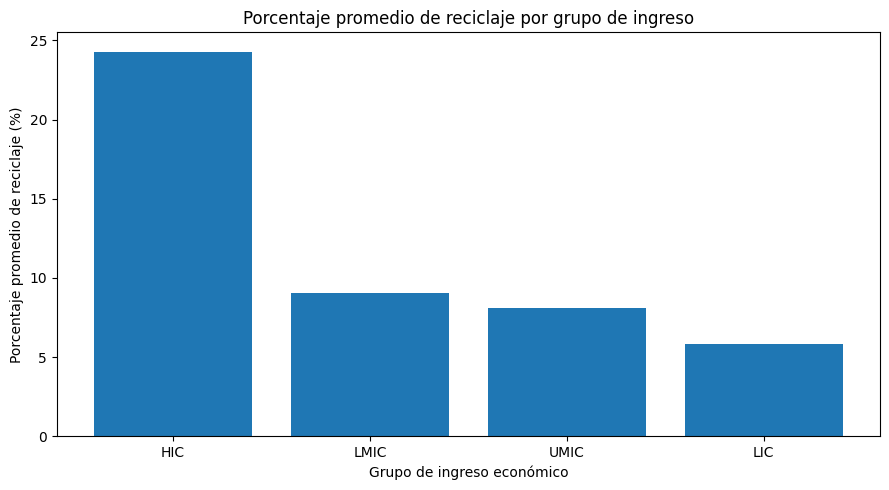

Promedio de reciclaje por grupo (%):


,Promedio de reciclaje (%)
grupo_ingreso,
HIC,24.29
LMIC,9.06
UMIC,8.13
LIC,5.81


In [7]:
import matplotlib.pyplot as plt

# Calcular el promedio de reciclaje por grupo de ingreso
promedio_grupos = (
    df_analisis.groupby("grupo_ingreso")["porcentaje_reciclaje"]
    .mean()
    .sort_values(ascending=False)
)

# Crear la gráfica
promedio_grupos.plot(kind="bar", figsize=(9, 5))

plt.title("Porcentaje promedio de reciclaje por grupo de ingreso")
plt.xlabel("Grupo de ingreso económico")
plt.ylabel("Porcentaje promedio de reciclaje (%)")
plt.xticks(rotation=0)

# Convertir proporciones a porcentajes en el eje vertical
valores = promedio_grupos.values * 100
plt.clf()

plt.figure(figsize=(9, 5))
plt.bar(promedio_grupos.index, valores)
plt.title("Porcentaje promedio de reciclaje por grupo de ingreso")
plt.xlabel("Grupo de ingreso económico")
plt.ylabel("Porcentaje promedio de reciclaje (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Mostrar los valores exactos
print("Promedio de reciclaje por grupo (%):")
display((promedio_grupos * 100).round(2).to_frame(
    name="Promedio de reciclaje (%)"
))


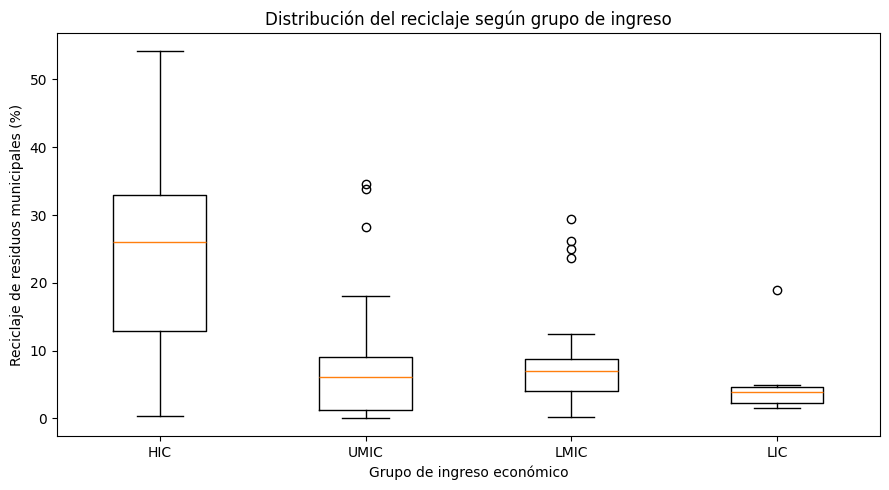

In [8]:

import matplotlib.pyplot as plt

# Convertir las proporciones a porcentajes
df_analisis["reciclaje_pct"] = (
    df_analisis["porcentaje_reciclaje"] * 100
)

# Organizar los datos por grupo
grupos = ["HIC", "UMIC", "LMIC", "LIC"]

datos = [
    df_analisis.loc[
        df_analisis["grupo_ingreso"] == grupo,
        "reciclaje_pct"
    ].dropna()
    for grupo in grupos
]

# Crear el diagrama de cajas
plt.figure(figsize=(9, 5))
plt.boxplot(datos, tick_labels=grupos)

plt.title("Distribución del reciclaje según grupo de ingreso")
plt.xlabel("Grupo de ingreso económico")
plt.ylabel("Reciclaje de residuos municipales (%)")
plt.tight_layout()
plt.show()


In [9]:
# Resumen del reciclaje por grupo de ingreso
resumen = df_analisis.groupby("grupo_ingreso")["reciclaje_pct"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

display(resumen)

,count,mean,median,min,max
grupo_ingreso,,,,,
HIC,65,24.29,26.02,0.31,54.18
LIC,6,5.81,3.91,1.50,18.90
LMIC,25,9.06,7.00,0.25,29.41
UMIC,34,8.13,6.05,0.06,34.55


In [10]:
print("Valores faltantes:")
print(df_analisis[[
    "grupo_ingreso",
    "porcentaje_reciclaje"
]].isnull().sum())

print("\nCantidad de países:")
print(df_analisis["pais"].nunique())

print("\nCantidad de filas duplicadas:")
print(df_analisis.duplicated().sum())

Valores faltantes:
grupo_ingreso           0
porcentaje_reciclaje    0
dtype: int64

Cantidad de países:
130

Cantidad de filas duplicadas:
0


In [11]:
resumen_grupos = (
    df_analisis.groupby("grupo_ingreso")["reciclaje_pct"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
    .round(2)
)

display(resumen_grupos)

,count,mean,median
grupo_ingreso,,,
HIC,65,24.29,26.02
LMIC,25,9.06,7.00
UMIC,34,8.13,6.05
LIC,6,5.81,3.91


In [12]:
from scipy.stats import kruskal

grupos = ["HIC", "UMIC", "LMIC", "LIC"]

datos_grupos = [
    df_analisis.loc[
        df_analisis["grupo_ingreso"] == grupo,
        "reciclaje_pct"
    ].dropna()
    for grupo in grupos
]

resultado = kruskal(*datos_grupos)

print("Estadístico de prueba:", round(resultado.statistic, 4))
print("Valor p:", round(resultado.pvalue, 4))


Estadístico de prueba: 43.0226
Valor p: 0.0


In [13]:
print(f"Valor p exacto aproximado: {resultado.pvalue:.10e}")

Valor p exacto aproximado: 2.4340195812e-09


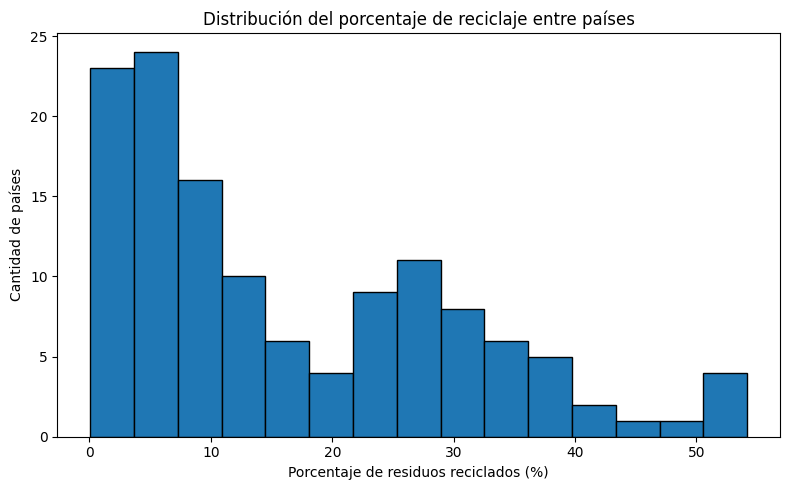

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    df_analisis["reciclaje_pct"].dropna(),
    bins=15,
    edgecolor="black"
)

plt.title("Distribución del porcentaje de reciclaje entre países")
plt.xlabel("Porcentaje de residuos reciclados (%)")
plt.ylabel("Cantidad de países")
plt.tight_layout()
plt.show()

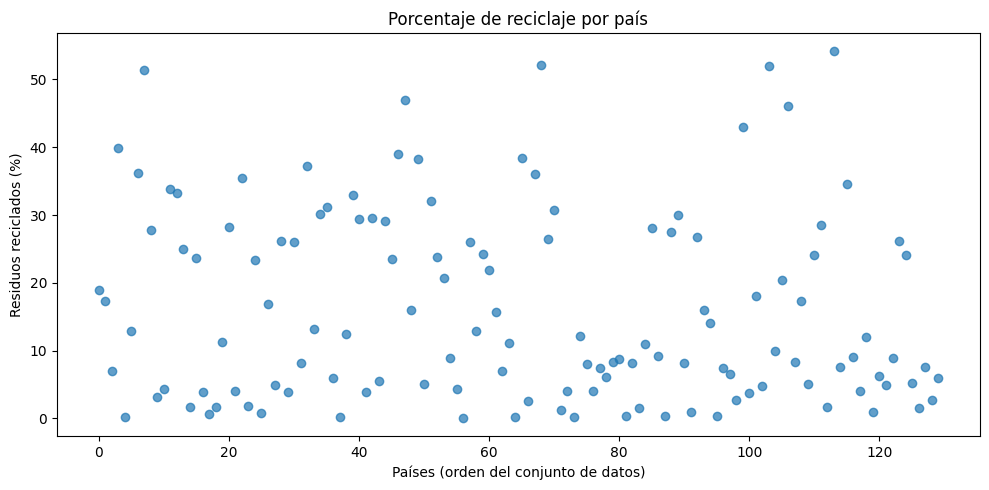

In [15]:
plt.figure(figsize=(10, 5))

plt.scatter(
    range(len(df_analisis)),
    df_analisis["reciclaje_pct"],
    alpha=0.7
)

plt.title("Porcentaje de reciclaje por país")
plt.xlabel("Países (orden del conjunto de datos)")
plt.ylabel("Residuos reciclados (%)")
plt.tight_layout()
plt.show()

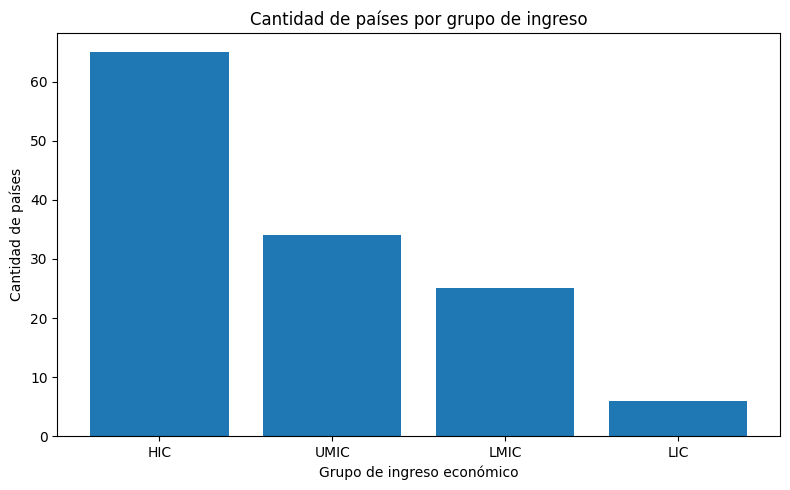

In [16]:
conteo = df_analisis["grupo_ingreso"].value_counts().reindex(
    ["HIC", "UMIC", "LMIC", "LIC"]
)

plt.figure(figsize=(8, 5))

plt.bar(conteo.index, conteo.values)

plt.title("Cantidad de países por grupo de ingreso")
plt.xlabel("Grupo de ingreso económico")
plt.ylabel("Cantidad de países")
plt.tight_layout()
plt.show()

In [17]:
import plotly.express as px
# Calcular el promedio de reciclaje por grupo de ingreso
resumen_interactivo = (
    df_analisis.groupby("grupo_ingreso", as_index=False)
    .agg(
        promedio_reciclaje=("reciclaje_pct", "mean"),
        cantidad_paises=("pais", "count")
    )
)

# Crear el gráfico interactivo
fig = px.bar(
    resumen_interactivo,
    x="grupo_ingreso",
    y="promedio_reciclaje",
    color="grupo_ingreso",
    hover_data=["cantidad_paises"],
    title="Promedio de reciclaje por grupo de ingreso",
    labels={
        "grupo_ingreso": "Grupo de ingreso económico",
        "promedio_reciclaje": "Promedio de reciclaje (%)",
        "cantidad_paises": "Cantidad de países"
    }
)

fig.show()

In [18]:
df_analisis["porcentaje_reciclaje"].describe().round(4)

,porcentaje_reciclaje
count,130.0000
mean,0.1628
std,0.1408
min,0.0006
25%,0.0442
50%,0.1121
75%,0.2665
max,0.5418
